# AMD［超威半导体］原生条件计算图：求解器如何少走主机调度

目标：沿着我们已有的源码与冻结结果，理解“设备端更新收敛条件 → 条件节点重放迭代体”，复算吞吐、核对状态，并生成独立复现命令。本篇默认读取历史结果，不构建运行库、不启动比赛重跑。

原项目：[条件计算图源码与补丁](https://github.com/Ethan-Chen-plus/mujoco-warp-amd-conditional-graph)。课程包保留原项目许可、运行器、比较脚本、协议和选定原始结果，指纹在 `notebooks/results/acceleration/source-manifest.json`。

## 核对来源与基准协议

**本次原生设备实测：2717.18124 → 2124.60063 毫秒，1.279倍；计时单位为1024世界×1000步。正确性检查未通过：原始容差1e-5，最大速度状态误差3.1233e-5。**


In [1]:
from pathlib import Path
import json, hashlib, platform, time
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

# Locate the course root from a source or exported notebook directory.
COURSE = next(p for p in [Path.cwd(), *Path.cwd().parents]
              if (p / "reproducibility/task-catalog.json").is_file())
EVIDENCE = COURSE / "notebooks/results/acceleration"
plt.rcParams.update({"figure.figsize": (8, 3.5), "font.size": 11})
print({"python": platform.python_version(), "evidence": str(EVIDENCE)})

manifest = json.loads((EVIDENCE / "source-manifest.json").read_text())
for relative, expected in manifest["files_sha256"].items():
    assert hashlib.sha256((EVIDENCE/relative).read_bytes()).hexdigest() == expected, relative
SOURCE = EVIDENCE / "conditional-graph-source"
result_dir = SOURCE / "results/mjwarp_native_conditional_amd395"
summary = json.loads((result_dir/"summary.json").read_text())
display({"hardware": summary["hardware"], "throughput_protocol": summary["protocol"],
         "paired_state_protocol": manifest["paired_state_protocol"],
         "runtime_sha256": summary["runtime_sha256"]})

print(json.loads((EVIDENCE / "amd-device-20261028-v1/device.json").read_text()))


{'python': '3.10.19', 'evidence': '/dev/shm/amd-acceleration-20261028-v1/course/notebooks/results/acceleration'}


{'hardware': {'host': 'AMD Ryzen AI Max+ 395',
  'gpu': 'Radeon 8060S',
  'arch': 'gfx1151',
  'rocm': '7.2.1',
  'hip_driver': '7.2'},
 'throughput_protocol': {'model': 'upstream/mujoco_warp/mujoco_warp/test_data/humanoid/humanoid.xml',
  'worlds': 1024,
  'steps': 1000,
  'warmup_steps': 4,
  'device': 'cuda:0',
  'nconmax': 128,
  'njmax': 128},
 'paired_state_protocol': '256 worlds x 100 steps; separate from throughput run',
 'runtime_sha256': '35189e8a2b85245f65670f39c0ca934159291e0408577c328a58d43b171f2c60'}

{'hostname': 'aup-NucBox-EVO-X2', 'python': '3.10.19 (main, Oct 21 2025, 16:43:05) [GCC 11.2.0]', 'torch': '2.11.0+rocm7.13.0a20260425', 'hip': '7.13.26162', 'gpu': 'Radeon 8060S Graphics', 'remote_reported_time': '2026-10-29T03:40:02.777923+08:00', 'work_mount': '/dev/shm', 'work_free_bytes': 18131025920, 'scope': 'shared AMD device; other services left running; no training or robot task evaluation'}


## 本次原生设备实测

本节显示本次设备实际执行的对照，历史结果在后文单独保留。主基准为1024世界、1000步，每种变体3次交替计时；状态检查为256世界、100步。共享设备的其他服务保持运行。

{'executed': True,
 'device': {'hostname': 'aup-NucBox-EVO-X2',
  'python': '3.10.19 (main, Oct 21 2025, 16:43:05) [GCC 11.2.0]',
  'torch': '2.11.0+rocm7.13.0a20260425',
  'hip': '7.13.26162',
  'gpu': 'Radeon 8060S Graphics',
  'remote_reported_time': '2026-10-29T03:40:02.777923+08:00',
  'work_mount': '/dev/shm',
  'work_free_bytes': 18131025920,
  'scope': 'shared AMD device; other services left running; no training or robot task evaluation'},
 'performance_worlds': 1024,
 'performance_steps': 1000,
 'timing_repeats_each': 3,
 'paired_state_worlds': 256,
 'paired_state_steps': 100,
 'median_run_s': {'eager': 2.7171812439337373, 'native': 2.124600625014864},
 'speed_ratio': 1.2789138871286587,
 'max_abs_state_errors': {'qpos': 5.632638931274414e-06,
  'qvel': 3.123283386230469e-05,
  'time': 0.0},
 'correctness_tolerance': 1e-05,
 'correctness_passed': False,
 'runtime_file': '/home/aup/tmp/rocm-hip-conditional-node-20260821/clr-build/hipamd/lib/libamdhip64.so.7.2.53211-b2451a4',
 '

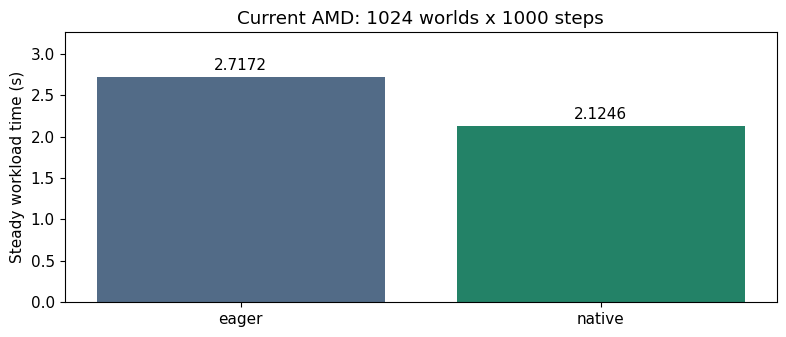

In [2]:
current = json.loads((EVIDENCE / "amd-device-20261028-v1/native-result.json").read_text())
display(current if not current.get("executed") else {k:v for k,v in current.items() if k != "records"})
if current.get("executed"):
    values = current["median_run_s"]
    fig, ax = plt.subplots()
    ax.bar(values.keys(), values.values(), color=["#526b87", "#238267"])
    ax.bar_label(ax.containers[0], fmt="%.4f", padding=3)
    ax.set(ylabel="Steady workload time (s)", title="Current AMD: 1024 worlds x 1000 steps", ylim=(0,max(values.values())*1.2))
    fig.tight_layout(); plt.show()


## 从历史时间复算加速
固定1024个世界、1000步，原生条件图与逐次调度执行相同物理工作。状态一致性来自另一个256世界、100步的配对检查。下面保留两种运行规模。

{'historical_throughput_speedup': 1.5617078637498625,
 'historical_runtime_reduction_percent': 35.96753764184355}

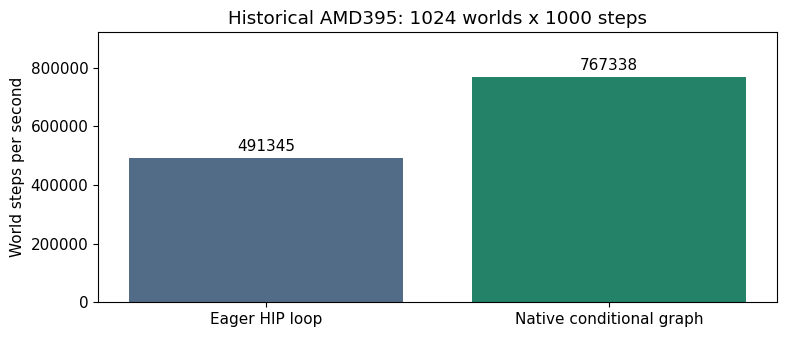

In [3]:
speedup = summary["eager_runtime_s"] / summary["native_runtime_s"]
reduction = 1 - summary["native_runtime_s"] / summary["eager_runtime_s"]
np.testing.assert_allclose(speedup, summary["throughput_speedup"], rtol=1e-9)
display({"historical_throughput_speedup": speedup,
         "historical_runtime_reduction_percent": reduction*100})
fig, ax = plt.subplots()
values = [summary["eager_worlds_per_second"], summary["native_worlds_per_second"]]
ax.bar(["Eager HIP loop", "Native conditional graph"], values, color=["#526b87", "#238267"])
ax.bar_label(ax.containers[0], fmt="%.0f", padding=3)
ax.set(ylabel="World steps per second", title="Historical AMD395: 1024 worlds x 1000 steps", ylim=(0,max(values)*1.2))
fig.tight_layout(); plt.show()


## 亲自检查物理状态
形状、有限值、位置、速度和时间一起核对。比较脚本应拒绝长度不一致的数组，不能通过截短后的配对掩盖缺失世界。协议容差为 `1e-5`。

In [4]:
native = json.loads((result_dir/"native_state.json").read_text())
eager = json.loads((result_dir/"eager_state.json").read_text())
errors = {}
for field in ["qpos", "qvel", "time"]:
    a, b = np.asarray(native[field]), np.asarray(eager[field])
    assert a.shape == b.shape, (field, a.shape, b.shape)
    assert np.isfinite(a).all() and np.isfinite(b).all()
    errors[field] = float(np.max(np.abs(a-b)))
    np.testing.assert_allclose(a, b, atol=1e-5, rtol=0)
assert native["worlds"] == eager["worlds"] == 256
assert native["steps"] == eager["steps"] == 100
display({"max_abs_errors": errors, "paired_worlds": 256, "paired_steps": 100})


{'max_abs_errors': {'qpos': 6.1793252825737e-07,
  'qvel': 9.5367431640625e-07,
  'time': 0.0},
 'paired_worlds': 256,
 'paired_steps': 100}

## 动手理解条件循环
传统循环每轮由主机检查条件并发起迭代。原生 HIP［异构计算接口］条件图将条件句柄放到设备，设备端设置器写入收敛条件，捕获的迭代体继续重放。固定次数展开则始终受最大迭代次数约束。

下面只用小型数组练习“不同元素何时收敛”，比较按需停止和固定上限掩码的结果；它不对设备速度作测量。

In [5]:
targets = np.array([0.5, 0.75, 0.875])
def solve(dynamic_stop):
    x = np.zeros_like(targets)
    active = np.ones_like(targets, dtype=bool)
    updates = np.zeros_like(targets, dtype=int)
    iterations = 0
    while iterations < 64:
        if dynamic_stop and not active.any():
            break
        x[active] += 0.5 * (targets[active] - x[active])
        updates += active
        active = np.abs(targets-x) > 1e-6
        iterations += 1
    return x, updates, iterations
conditional, cond_updates, conditional_iterations = solve(True)
fixed, fixed_updates, fixed_iterations = solve(False)
np.testing.assert_array_equal(conditional, fixed)
np.testing.assert_array_equal(cond_updates, fixed_updates)
display({"conditional_body_checks": conditional_iterations, "fixed_body_checks": fixed_iterations,
         "per_element_updates": cond_updates.tolist(), "same_solution": True})


{'conditional_body_checks': 20,
 'fixed_body_checks': 64,
 'per_element_updates': [19, 20, 20],
 'same_solution': True}

## 对照完整接触场景
完整场景还包含碰撞检测、约束组装和唤醒逻辑。下表从原始记录计算条件图相对静态图的吞吐比，并同时列出长轨迹的位置、速度误差。误差超过协议容差的行只作为性能与集成诊断，不能作为物理等价加速结论。

In [6]:
rows = []
for phase in ["settled_long", "active_long", "wake_cycle_long"]:
    record = json.loads((SOURCE / "results/aloha_physical_graph_amd395" / phase / "summary.json").read_text())
    errors = record["state_error_vs_static"]["native"]
    rows.append({"phase": record["phase"], "native/static": record["native_vs_static_speedup"],
                 "qpos_error": errors["qpos_max_abs"], "qvel_error": errors["qvel_max_abs"],
                 "long_state_gate_1e-5": max(errors.values()) <= 1e-5})
display(rows)
assert all(not row["long_state_gate_1e-5"] for row in rows)


[{'phase': 'settled',
  'native/static': 0.9975597700279163,
  'qpos_error': 0.19645218923687935,
  'qvel_error': 1.985805394826457,
  'long_state_gate_1e-5': False},
 {'phase': 'active',
  'native/static': 1.0979436130349565,
  'qpos_error': 0.46966710686683655,
  'qvel_error': 6.122118443250656,
  'long_state_gate_1e-5': False},
 {'phase': 'wake_cycle',
  'native/static': 0.75016124648232,
  'qpos_error': 0.09465556591749191,
  'qvel_error': 0.41657219477929175,
  'long_state_gate_1e-5': False}]

## 生成复现命令与练习
复现需要原项目完整源码、已有匹配解释器、含实验条件节点符号的独立运行库。普通安装缺少这些符号时先完成隔离构建；本篇不自动安装或替换系统运行库。命令将环境设置限制在子进程中，输出写到14TB数据盘的新目录。当前环境的短练习不修改其他服务。

准备后可自行执行下方打印的命令。运行器分别启动两种变体、状态检查并保存内容指纹；执行前检查当前设备空闲与存储空间。

In [7]:
import shlex
PROJECT = Path("/path/to/mujoco-warp-amd-conditional-graph")
ENVIRONMENT = Path("/data/Data14TB/envs/mujoco-warp-amd")
PATCHED_LIBRARY = Path("/path/to/patched/libamdhip64.so")
OUTPUT = Path("/data/Data14TB/01Proj/every-embodied-amd/acceleration-learner-run")
settings = {"ROOT": str(PROJECT), "ENV": str(ENVIRONMENT),
            "HIP_CLR_LIB": str(PATCHED_LIBRARY), "OUT": str(OUTPUT),
            "WORLDS": "1024", "STEPS": "1000"}
command = "env " + " ".join(k+"="+shlex.quote(v) for k,v in settings.items())
command += " bash " + shlex.quote(str(PROJECT/"scripts/run_native_mjwarp_benchmark.sh"))
print(command)
print("Command only; no historical benchmark is rerun by this notebook.")


env ROOT=/path/to/mujoco-warp-amd-conditional-graph ENV=/data/Data14TB/envs/mujoco-warp-amd HIP_CLR_LIB=/path/to/patched/libamdhip64.so OUT=/data/Data14TB/01Proj/every-embodied-amd/acceleration-learner-run WORLDS=1024 STEPS=1000 bash /path/to/mujoco-warp-amd-conditional-graph/scripts/run_native_mjwarp_benchmark.sh
Command only; no historical benchmark is rerun by this notebook.


练习：在数组循环中把容差改为 `1e-8`，观察迭代次数；随后阅读课程包内原始 `scripts/run_mjwarp_variant.py`，找出预热、同步、计时边界和状态保存位置。真实复现时保留相同模型、控制、精度、求解器配置和分母，再判断修改带来的收益。